In [26]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier ,plot_tree
from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

In [6]:
data = {
'Age': np.random.randint(20, 60, 100),
'PurchaseFrequency': np.random.uniform(0.5, 5, 100).round(1),
'RespondedToCampaign': np.random.choice([0, 1], 100, p=[0.6, 0.4])
}
# Make response somewhat dependent on younger age and higher frequency
for i in range(100):
    if data['Age'][i] < 35 and data['PurchaseFrequency'][i] > 3:
        data['RespondedToCampaign'][i] = 1
    elif data['Age'][i] > 50 and data['PurchaseFrequency'][i] < 1.5:
        data['RespondedToCampaign'][i] = 0

In [7]:
df = pd.DataFrame(data)
X = df[['Age', 'PurchaseFrequency']]
y = df['RespondedToCampaign']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
random_state=42)

In [8]:
clf = DecisionTreeClassifier(max_depth=3)

In [9]:
clf.fit(X_train , y_train)

DecisionTreeClassifier(max_depth=3)

In [11]:
y_pred = clf.predict(X_test)

In [12]:
accuracy_score(y_test , y_pred)

0.7666666666666667

[Text(0.4230769230769231, 0.875, 'x[1] <= 1.3\ngini = 0.493\nsamples = 100.0%\nvalue = [0.443, 0.557]'),
 Text(0.15384615384615385, 0.625, 'x[0] <= 45.5\ngini = 0.18\nsamples = 14.3%\nvalue = [0.9, 0.1]'),
 Text(0.28846153846153844, 0.75, 'True  '),
 Text(0.07692307692307693, 0.375, 'gini = 0.0\nsamples = 11.4%\nvalue = [1.0, 0.0]'),
 Text(0.23076923076923078, 0.375, 'x[0] <= 52.0\ngini = 0.5\nsamples = 2.9%\nvalue = [0.5, 0.5]'),
 Text(0.15384615384615385, 0.125, 'gini = 0.0\nsamples = 1.4%\nvalue = [0.0, 1.0]'),
 Text(0.3076923076923077, 0.125, 'gini = 0.0\nsamples = 1.4%\nvalue = [1.0, 0.0]'),
 Text(0.6923076923076923, 0.625, 'x[0] <= 38.5\ngini = 0.464\nsamples = 85.7%\nvalue = [0.367, 0.633]'),
 Text(0.5576923076923077, 0.75, '  False'),
 Text(0.5384615384615384, 0.375, 'x[1] <= 3.0\ngini = 0.269\nsamples = 35.7%\nvalue = [0.16, 0.84]'),
 Text(0.46153846153846156, 0.125, 'gini = 0.469\nsamples = 11.4%\nvalue = [0.375, 0.625]'),
 Text(0.6153846153846154, 0.125, 'gini = 0.111\nsampl

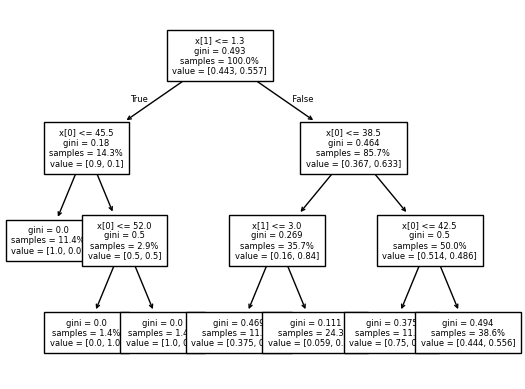

In [24]:
plot_tree(clf  , fontsize = 6 , proportion = True)

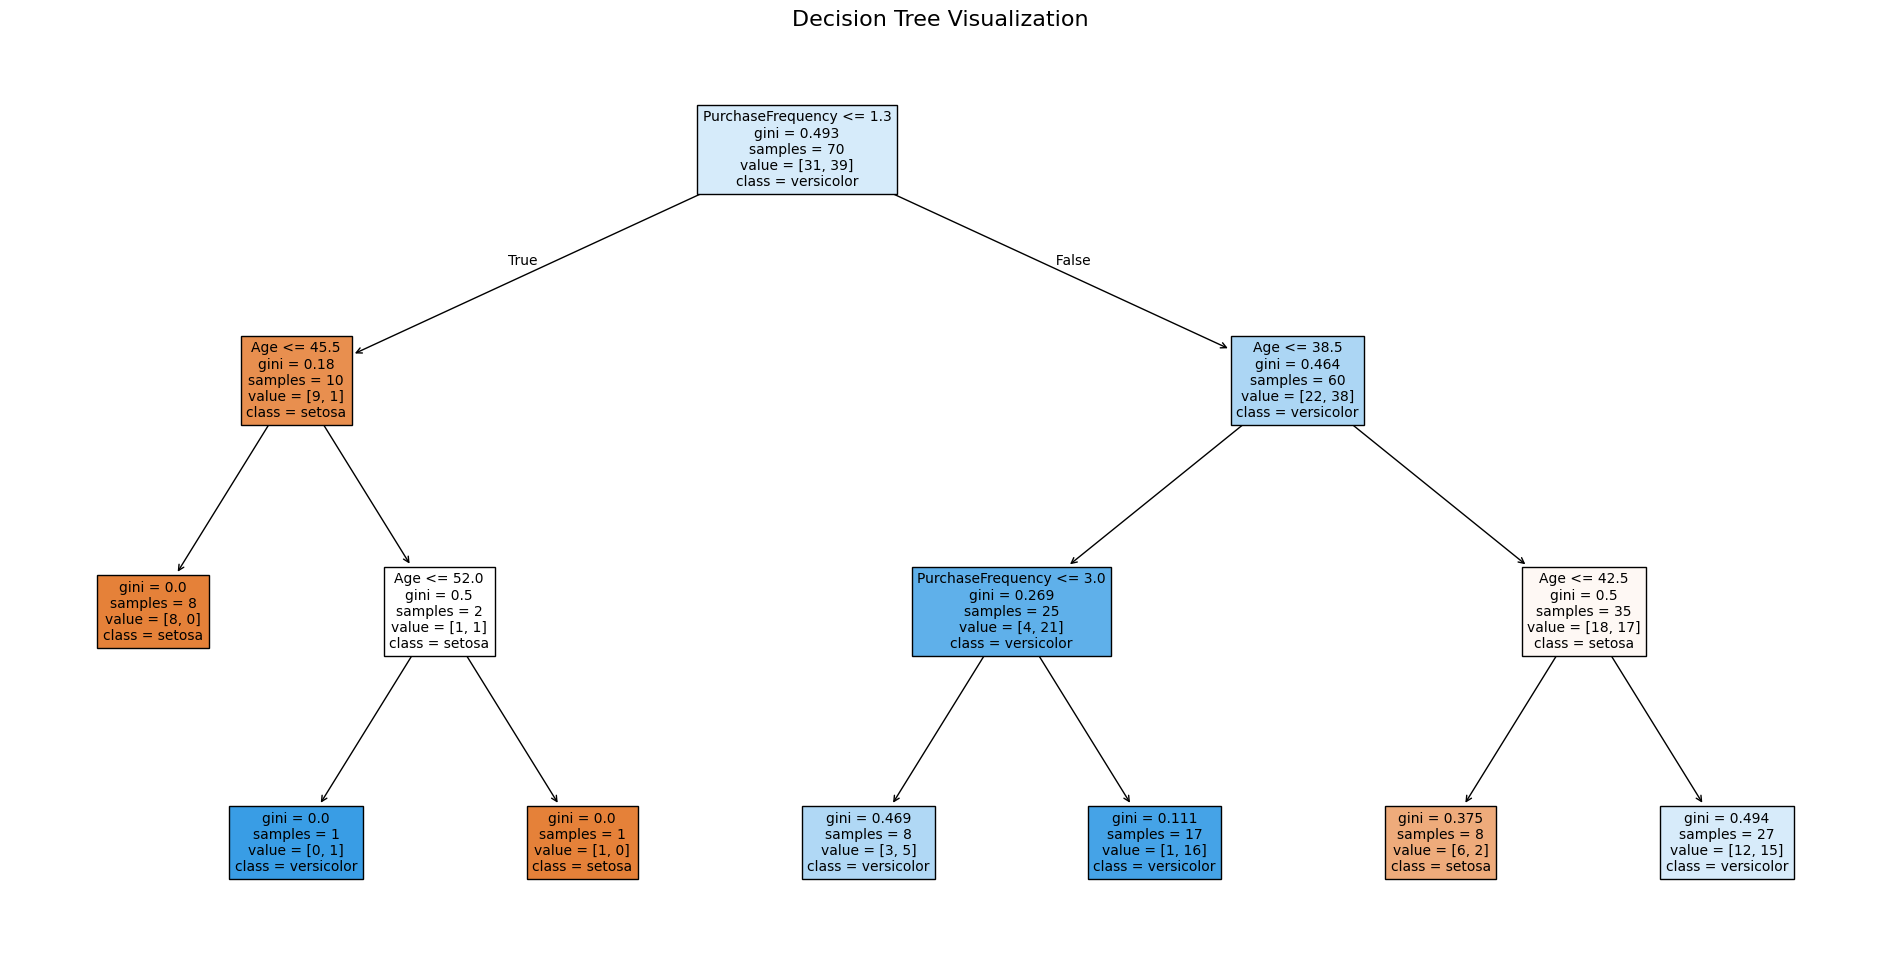

In [31]:
plt.figure(figsize=(24, 12))

plot_tree(
    clf,
    filled=True,
    feature_names=X.columns,
    class_names=['setosa', 'versicolor', 'virginica'],
    fontsize=10,  
)

plt.title("Decision Tree Visualization", fontsize=16)
plt.show()

In [32]:
from sklearn.linear_model import LogisticRegression


In [33]:
np.random.seed(42)
keywords = np.random.randint(0, 10, 100) # Number of suspicious keywords
# Higher keywords = higher spam probability
spam_prob = 1 / (1 + np.exp(-(keywords - 5))) # Sigmoid-like function
is_spam = (np.random.rand(100) < spam_prob).astype(int)
df = pd.DataFrame({'NumSuspiciousKeywords': keywords, 'IsSpam': is_spam})
X = df[['NumSuspiciousKeywords']] # Features must be 2D
y = df['IsSpam']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
random_state=42)

In [34]:
clf2 = LogisticRegression()

In [35]:
clf2.fit(X_train , y_train )

LogisticRegression()

In [53]:
X_train.shape

(70, 1)

In [37]:
y_pred = clf2.predict(X_test)

In [49]:
intercept = clf2.intercept_
coeff = clf2.coef_

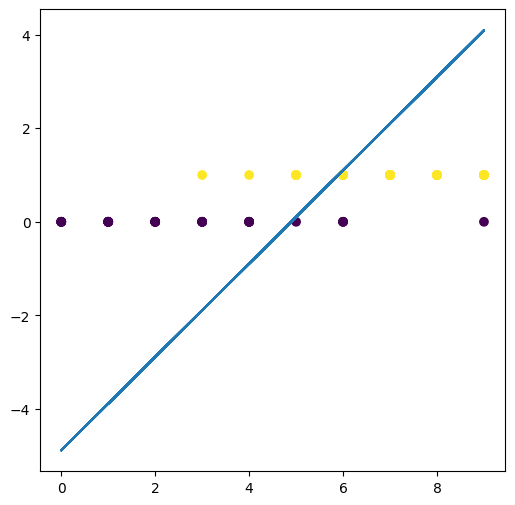

In [52]:
plt.figure(figsize = (6,6))
plt.scatter(X_train ,y_train,c=y_train )
plt.plot(X_train , intercept + coeff*X_train)
plt.show()

In [54]:
from sklearn.model_selection import cross_val_score

In [ ]:
scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring='accuracy'
)

# Print accuracy of each fold
for i, score in enumerate(scores, start=1):
    print(f"Fold {i} Accuracy: {score:.4f}")

# Average accuracy
print("\nAverage Accuracy:", np.mean(scores))